# Quickstart — TimesFM + Schaake Shuffle

Este notebook sirve como punto de entrada para una persona que utiliza el repositorio por primera vez.

La generación de escenarios **no se reimplementa aquí**. La función principal llama al mismo módulo utilizado por la CLI:

```text
wind_scenarios.cli.generate
```

y luego utiliza:

```text
wind_scenarios.evaluation
```

para exportar el `ground_truth.csv` **después** de completar la generación.

De esta forma se mantiene explícita la separación:

```text
datos conocidos -> TimesFM -> Schaake Shuffle -> escenarios
                                                 |
                                                 v
                                   evaluación ex-post
                                   ground_truth.csv
```

Además del viento, la versión actual del pipeline genera automáticamente escenarios de potencia para Alto Baguales mediante la curva suministrada en:

```text
data/power_curves/alto_baguales_3p5mw.csv
```

El máximo de la curva utilizada es **3.5 MW por turbina**, exactamente como aparece en el código/CSV fuente recibido. La conversión se aplica solamente después de obtener los escenarios finales de viento.


## 1. Preparar el entorno

Desde PowerShell, en la raíz del repositorio:

```powershell
uv sync
```

Para abrir Jupyter Lab sin agregar Jupyter permanentemente al proyecto:

```powershell
uv run --with jupyter jupyter lab
```

El dataset debe estar disponible en:

```text
data/wind_ab_daily.csv
```

con columnas:

```text
DATE,WIND
```

In [1]:
import sys
print(sys.executable)

c:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\.venv\Scripts\python.exe


In [2]:
from __future__ import annotations

import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image as IPythonImage, display

from wind_scenarios.data import (
    DEFAULT_DATA_PATH,
    PROJECT_ROOT,
)
from wind_scenarios.evaluation import (
    load_ground_truth,
    save_ground_truth,
)

print("Python del kernel:")
print(sys.executable)

print("\nRaíz del proyecto:")
print(PROJECT_ROOT)

print("\nDataset:")
print(DEFAULT_DATA_PATH)

Python del kernel:
c:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\.venv\Scripts\python.exe

Raíz del proyecto:
C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration

Dataset:
C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\data\wind_ab_daily.csv


## 2. Función de generación

Los parámetros principales son:

- `origin`: primer día del forecast;
- `historical_method`: `same_calendar_date` o `moving_window`;
- `context_len`: longitud del contexto entregado a TimesFM;
- `horizon_len`: cantidad de días futuros a pronosticar.

La función también permite configurar el caso de ventanas móviles.

`export_ground_truth=True` indica que, una vez terminada la generación, se escriba:

```text
ground_truth.csv
```

en la misma carpeta de resultados.

In [3]:
def generate_wind_scenarios(
    origin: str,
    historical_method: str = "same_calendar_date",
    context_len: int = 32,
    horizon_len: int = 28,
    *,
    n_scenarios: int | None = None,
    window_radius_days: int = 15,
    min_start_distance_days: int = 0,
    selection: str = "closest",
    device: str = "auto",
    export_ground_truth: bool = True,
    data_path: str | Path = DEFAULT_DATA_PATH,
    output_root: str | Path = PROJECT_ROOT / "outputs" / "schaake",
) -> dict:
    """
    Run zero-shot TimesFM + Schaake Shuffle using the repository's
    generate module.

    Ground truth is loaded only after generation has completed.
    """
    if historical_method not in {
        "same_calendar_date",
        "moving_window",
    }:
        raise ValueError(
            "historical_method must be "
            "'same_calendar_date' or 'moving_window'."
        )

    if context_len <= 0:
        raise ValueError(
            "context_len must be positive."
        )

    if horizon_len <= 0:
        raise ValueError(
            "horizon_len must be positive."
        )

    if device not in {
        "auto",
        "cpu",
        "cuda",
    }:
        raise ValueError(
            "device must be 'auto', 'cpu' or 'cuda'."
        )

    origin_ts = pd.Timestamp(
        origin
    ).normalize()

    data_path = Path(
        data_path
    )

    output_root = Path(
        output_root
    )

    command = [
        sys.executable,
        "-m",
        "wind_scenarios.cli.generate",
        "--origin",
        origin_ts.date().isoformat(),
        "--historical_method",
        historical_method,
        "--context_len",
        str(context_len),
        "--horizon_len",
        str(horizon_len),
        "--device",
        device,
        "--data_path",
        str(data_path),
        "--output_dir",
        str(output_root),
    ]

    if n_scenarios is not None:
        command.extend(
            [
                "--n_scenarios",
                str(n_scenarios),
            ]
        )

    if historical_method == "moving_window":
        command.extend(
            [
                "--window_radius_days",
                str(window_radius_days),
                "--min_start_distance_days",
                str(min_start_distance_days),
                "--selection",
                selection,
            ]
        )

    print(
        "=== TIMESFM + SCHAAKE SHUFFLE ==="
    )
    print(
        " ".join(
            f'"{part}"'
            if " " in part
            else part
            for part in command
        )
    )
    print()

    # The subprocess must finish successfully before any future
    # observation is read for evaluation.
    subprocess.run(
        command,
        cwd=PROJECT_ROOT,
        check=True,
    )

    output_dir = (
        output_root
        / origin_ts.date().isoformat()
    )

    ground_truth_path = None

    if export_ground_truth:
        ground_truth_path = save_ground_truth(
            origin=origin_ts,
            horizon_len=horizon_len,
            output_dir=output_dir,
            data_path=data_path,
        )

    paths = {
        "output_dir": output_dir,
        "context": (
            output_dir
            / "context.csv"
        ),
        "quantiles": (
            output_dir
            / "timesfm_quantiles.csv"
        ),
        "historical": (
            output_dir
            / "historical_trajectories.csv"
        ),
        "metadata": (
            output_dir
            / "historical_metadata.csv"
        ),
        "ranks": (
            output_dir
            / "historical_ranks.csv"
        ),
        "pseudo_observations": (
            output_dir
            / "empirical_pseudo_observations.csv"
        ),
        "assigned_probabilities": (
            output_dir
            / "assigned_probabilities.csv"
        ),
        "marginals": (
            output_dir
            / "timesfm_discretized_marginals.csv"
        ),
        "scenarios": (
            output_dir
            / "scenarios.csv"
        ),
        "power_scenarios": (
            output_dir
            / "power_scenarios_alto_baguales.csv"
        ),
        "ground_truth": ground_truth_path,
    }

    result = {
        "origin": origin_ts,
        "historical_method": historical_method,
        "context_len": context_len,
        "horizon_len": horizon_len,
        "output_dir": output_dir,
        "paths": paths,
        "context": pd.read_csv(
            paths["context"],
            parse_dates=["DATE"],
        ),
        "quantiles": pd.read_csv(
            paths["quantiles"],
            parse_dates=["DATE"],
        ),
        "scenarios": pd.read_csv(
            paths["scenarios"],
        ),
    }

    if paths["power_scenarios"].exists():
        result["power_scenarios"] = pd.read_csv(
            paths["power_scenarios"],
        )

    if ground_truth_path is not None:
        result["ground_truth"] = (
            pd.read_csv(
                ground_truth_path,
                parse_dates=["DATE"],
            )
        )

    print()
    print(
        "=== GENERACIÓN COMPLETADA ==="
    )
    print(
        f"Output:        {output_dir}"
    )
    print(
        f"Context:       {result['context'].shape}"
    )
    print(
        f"Quantiles:     {result['quantiles'].shape}"
    )
    print(
        f"Scenarios:     {result['scenarios'].shape}"
    )

    if "power_scenarios" in result:
        print(
            f"Power:         {result['power_scenarios'].shape}"
        )

    if ground_truth_path is not None:
        print(
            "Ground truth:  "
            f"{result['ground_truth'].shape}"
        )
        print(
            f"Saved:         {ground_truth_path}"
        )

    return result

## 3. Caso base: 32 días de contexto y 28 días de forecast

Equivale conceptualmente a:

```powershell
uv run generate-wind-scenarios `
    --origin 2014-04-01 `
    --historical_method same_calendar_date `
    --context_len 32 `
    --horizon_len 28
```

In [4]:
result = generate_wind_scenarios(
    origin="2014-04-01",
    historical_method="same_calendar_date",
    context_len=32,
    horizon_len=28,
)

=== TIMESFM + SCHAAKE SHUFFLE ===
c:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\.venv\Scripts\python.exe -m wind_scenarios.cli.generate --origin 2014-04-01 --historical_method same_calendar_date --context_len 32 --horizon_len 28 --device auto --data_path C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\data\wind_ab_daily.csv --output_dir C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake


=== GENERACIÓN COMPLETADA ===
Output:        C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01
Context:       (32, 2)
Quantiles:     (28, 10)
Scenarios:     (34, 29)
Power:         (34, 29)
Ground truth:  (28, 3)
Saved:         C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\ground_truth.csv


## 4. Revisar resultados

In [5]:
print("Carpeta:")
print(result["output_dir"])

print("\nArchivos:")
for name, path in result["paths"].items():
    if path is not None:
        print(
            f"{name:24s} -> {path}"
        )

print("\nContexto:")
display(
    result["context"].head()
)

print("\nCuantiles TimesFM:")
display(
    result["quantiles"].head()
)

print("\nGround truth:")
display(
    result["ground_truth"].head()
)

Carpeta:
C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01

Archivos:
output_dir               -> C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01
context                  -> C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\context.csv
quantiles                -> C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\timesfm_quantiles.csv
historical               -> C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\historical_trajectories.csv
metadata                 -> C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\historical_metadata.csv
ranks                    -> C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\historical_ranks.csv
pseudo_observations      -> C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\empirical_pse

,DATE,WIND
0,2014-02-28,10.480250
1,2014-03-01,7.447667
2,2014-03-02,5.846250
3,2014-03-03,9.485416
4,2014-03-04,13.685666



Cuantiles TimesFM:


,DATE,q10,q20,q30,q40,q50,q60,q70,q80,q90
0,2014-04-01,4.102023,5.937930,7.218930,8.167838,9.102195,10.081494,11.114176,12.426137,14.452562
1,2014-04-02,5.327481,7.290719,8.640966,9.815954,10.800550,11.916790,13.149405,14.460472,16.651424
2,2014-04-03,6.030444,8.023296,9.515779,10.731263,11.770260,12.920630,14.204950,15.675874,17.895536
3,2014-04-04,5.293365,7.480707,8.933940,10.083990,11.192452,12.408382,13.647228,15.175515,17.519860
4,2014-04-05,4.008550,6.166262,7.630039,8.865393,9.966465,11.216512,12.528584,13.990326,16.365042



Ground truth:


,DATE,WIND,LEAD_DAY
0,2014-04-01,4.176667,1
1,2014-04-02,6.276250,2
2,2014-04-03,2.512833,3
3,2014-04-04,6.925917,4
4,2014-04-05,5.428000,5


## 5. Conversión viento → potencia para Alto Baguales

Después de que Schaake Shuffle genera la matriz final de escenarios de viento, el pipeline aplica la curva de potencia tabulada recibida:

```text
data/power_curves/alto_baguales_3p5mw.csv
```

La función fuente se representa por tramos lineales. Entre dos puntos consecutivos $(v_k,P_k)$ y $(v_{k+1},P_{k+1})$:

$$
P(v)=h_{0,k}+h_k v,
$$

con

$$
h_k=\frac{P_{k+1}-P_k}{v_{k+1}-v_k},
\qquad
h_{0,k}=P_k-h_kv_k.
$$

La implementación actual conserva el máximo de la curva suministrada:

$$
P_{\max}=3500\ \mathrm{kW}=3.5\ \mathrm{MW}
$$

por turbina.

La fuente dentro del repositorio recibido es:

```text
wind_curve.csv
        ↓
power_wind_curve_lineal.py
        ↓
power_curve_segments.csv
        ↓
wind_to_power.py
```

El archivo generado por nuestro pipeline es:

```text
power_scenarios_alto_baguales.csv
```

y mantiene la misma forma `L x H` que `scenarios.csv`.

> Nota: los escenarios actuales de viento son diarios. Por ahora esta capa debe interpretarse como una transformación de potencia equivalente de la velocidad diaria, no como una integración horaria exacta de energía.


## 5. Visualización de viento y potencia

El módulo `wind_scenarios.cli.visualize` ahora dispone de dos modos adicionales:

```text
wind_power
```

compara las dos trayectorias en el tiempo:

$$
t \rightarrow v_t
\qquad\text{y}\qquad
t \rightarrow P_t
$$

usando dos ejes Y, porque velocidad `[m/s]` y potencia `[MW]` tienen unidades distintas.

El modo:

```text
power_curve
```

muestra la relación física:

$$
v_t \rightarrow P_t
$$

superponiendo los puntos del escenario sobre la curva de potencia de Alto Baguales.

Estas visualizaciones se construyen a partir de los CSV ya generados, por lo que **no vuelven a ejecutar TimesFM ni Schaake Shuffle**.

In [6]:
def visualize_result(
    result: dict,
    *,
    mode: str = "single",
    scenario_number: int = 1,
    all_quantiles: bool = False,
    export_all: bool = False,
    display_plot: bool = True,
    data_path: str | Path = DEFAULT_DATA_PATH,
) -> Path:
    """
    Generate a plot from existing CSV outputs without rerunning TimesFM.

    Supported modes
    ---------------
    single:
        One wind scenario + TimesFM quantiles + ground truth.

    fan:
        Fan plot of all wind scenarios.

    wind_power:
        Generated wind and calculated power vs forecast date.

    power_curve:
        Generated (wind, power) points over the Alto Baguales
        turbine power curve.
    """
    if mode not in {
        "single",
        "fan",
        "wind_power",
        "power_curve",
    }:
        raise ValueError(
            "mode must be one of: "
            "'single', 'fan', 'wind_power', 'power_curve'."
        )

    output_dir = Path(
        result["output_dir"]
    )

    command = [
        sys.executable,
        "-m",
        "wind_scenarios.cli.visualize",
        "--input_dir",
        str(output_dir),
        "--data_path",
        str(data_path),
        "--mode",
        mode,
    ]

    if all_quantiles:
        command.append(
            "--all_quantiles"
        )

    if export_all:
        command.append(
            "--export_all"
        )
    elif mode != "fan":
        command.extend(
            [
                "--scenario_number",
                str(scenario_number),
            ]
        )

    print(
        "=== VISUALIZACIÓN ==="
    )
    print(
        " ".join(
            f'"{part}"'
            if " " in part
            else part
            for part in command
        )
    )

    subprocess.run(
        command,
        cwd=PROJECT_ROOT,
        check=True,
    )

    if export_all:
        if mode == "single":
            plot_path = output_dir / (
                "scenario_plots_all_quantiles"
                if all_quantiles
                else "scenario_plots"
            )
        elif mode == "wind_power":
            plot_path = (
                output_dir
                / "wind_power_plots"
            )
        elif mode == "power_curve":
            plot_path = (
                output_dir
                / "power_curve_plots"
            )
        else:
            raise ValueError(
                "export_all is not used with fan mode."
            )

        print(
            f"Plots guardados en: {plot_path}"
        )
        return plot_path

    if mode == "fan":
        plot_path = output_dir / (
            "scenario_fan_all_quantiles.png"
            if all_quantiles
            else "scenario_fan.png"
        )
    elif mode == "single":
        suffix = (
            "_all_quantiles"
            if all_quantiles
            else ""
        )
        plot_path = (
            output_dir
            / (
                f"scenario_{scenario_number:03d}"
                f"{suffix}.png"
            )
        )
    elif mode == "wind_power":
        plot_path = (
            output_dir
            / (
                f"scenario_{scenario_number:03d}"
                "_wind_power.png"
            )
        )
    else:
        plot_path = (
            output_dir
            / (
                f"scenario_{scenario_number:03d}"
                "_power_curve.png"
            )
        )

    if not plot_path.exists():
        raise FileNotFoundError(
            "No se creó el gráfico esperado: "
            f"{plot_path}"
        )

    print(
        f"Gráfico guardado: {plot_path}"
    )

    if display_plot:
        display(
            IPythonImage(
                filename=str(plot_path)
            )
        )

    return plot_path

=== VISUALIZACIÓN ===
c:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\.venv\Scripts\python.exe -m wind_scenarios.cli.visualize --input_dir C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01 --data_path C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\data\wind_ab_daily.csv --mode wind_power --scenario_number 1
Gráfico guardado: C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\scenario_001_wind_power.png


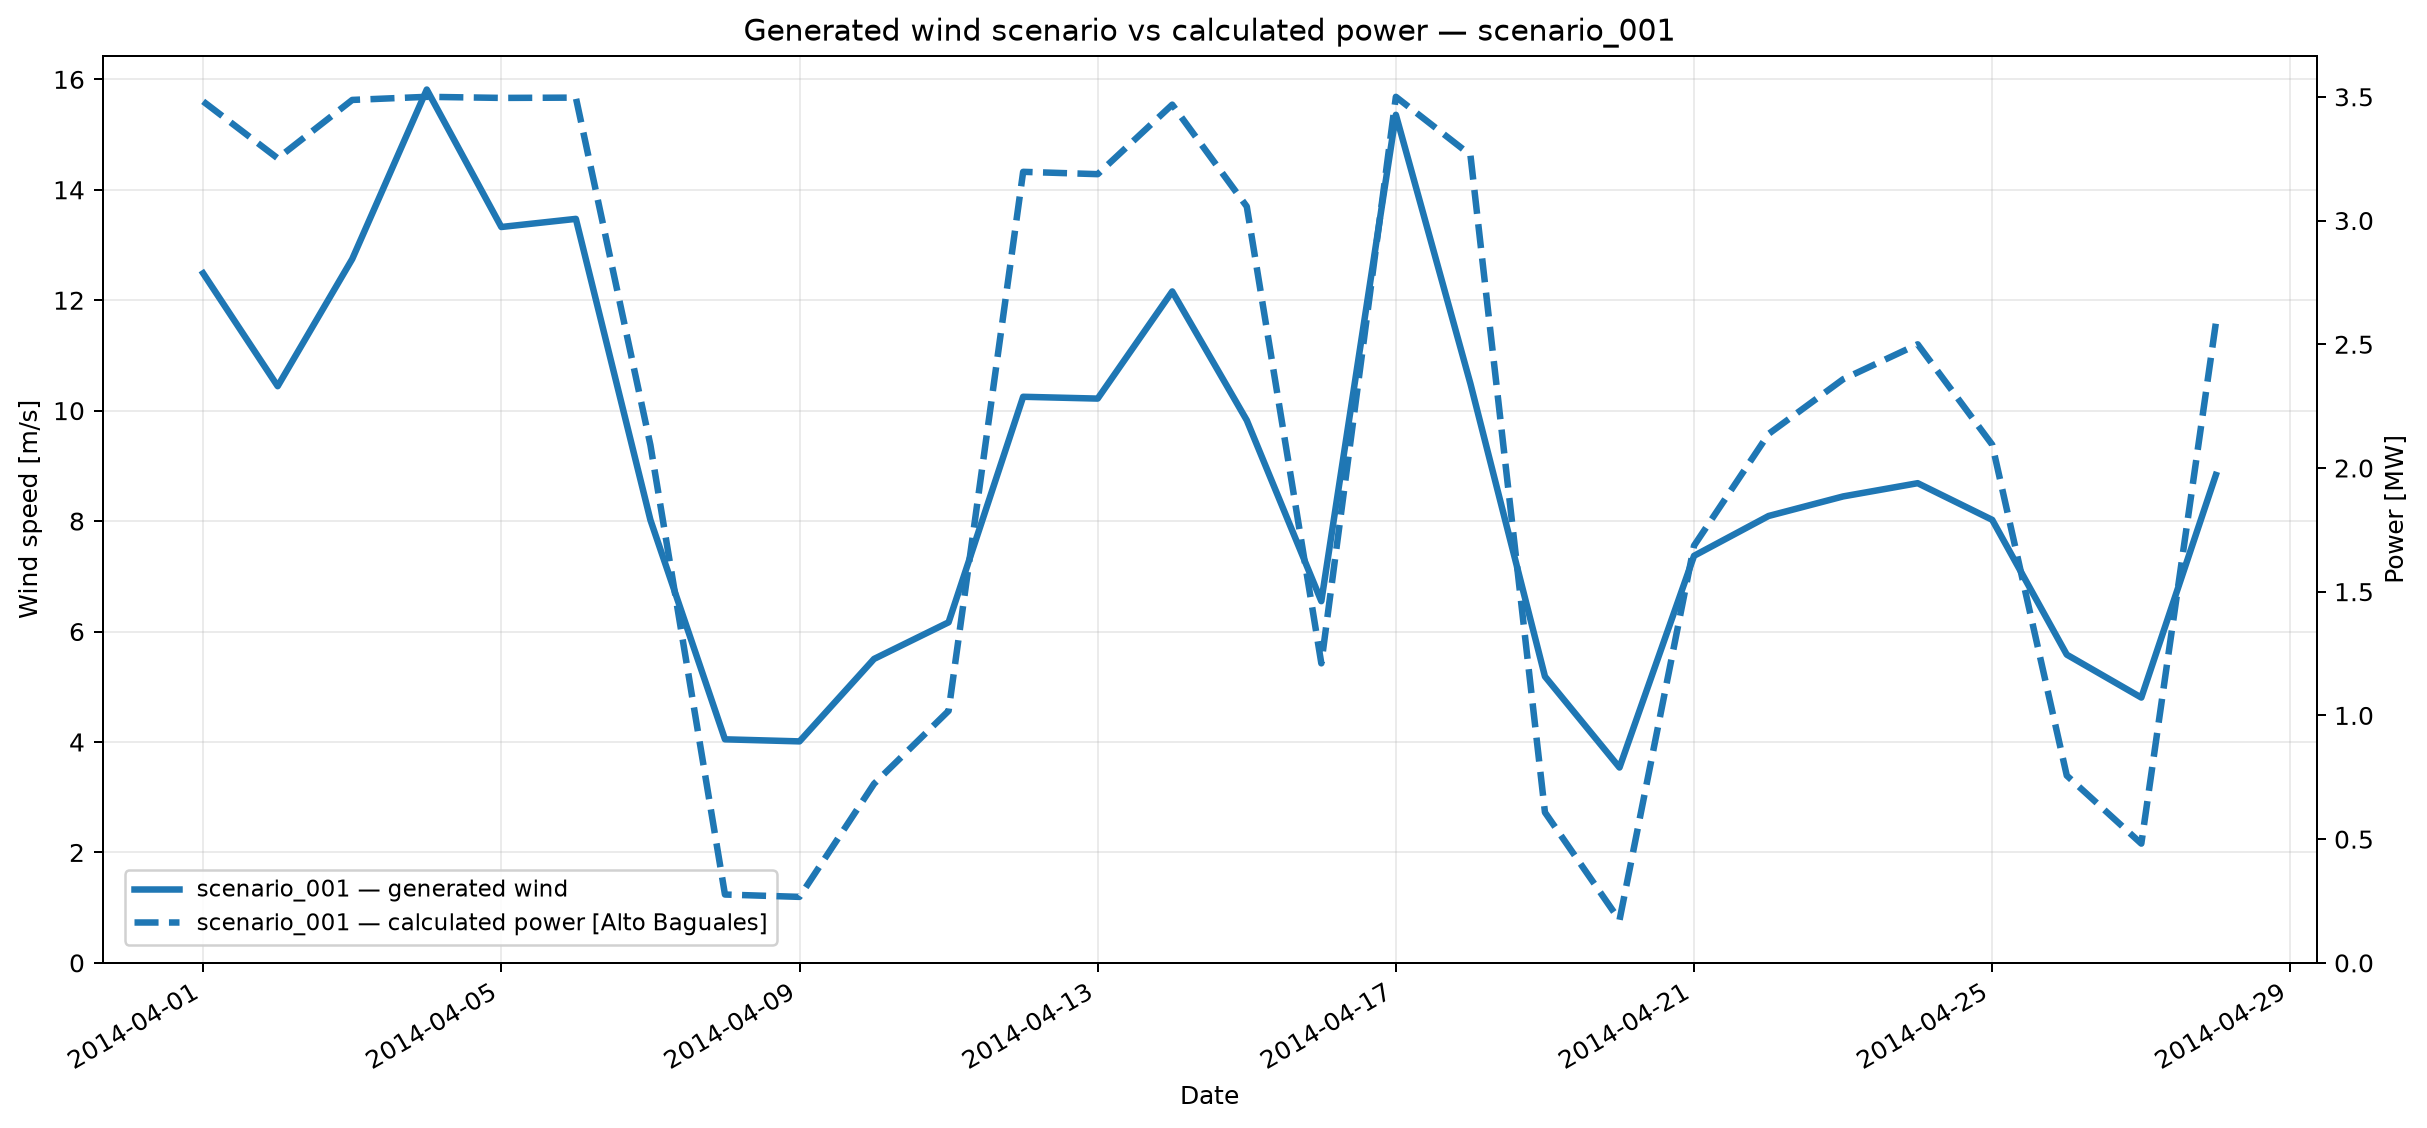

In [13]:
# Trayectoria temporal:
# velocidad de viento generada vs potencia calculada.
wind_power_plot = visualize_result(
    result,
    mode="wind_power",
    scenario_number=1,
)

=== VISUALIZACIÓN ===
c:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\.venv\Scripts\python.exe -m wind_scenarios.cli.visualize --input_dir C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01 --data_path C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\data\wind_ab_daily.csv --mode power_curve --scenario_number 1
Gráfico guardado: C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\scenario_001_power_curve.png


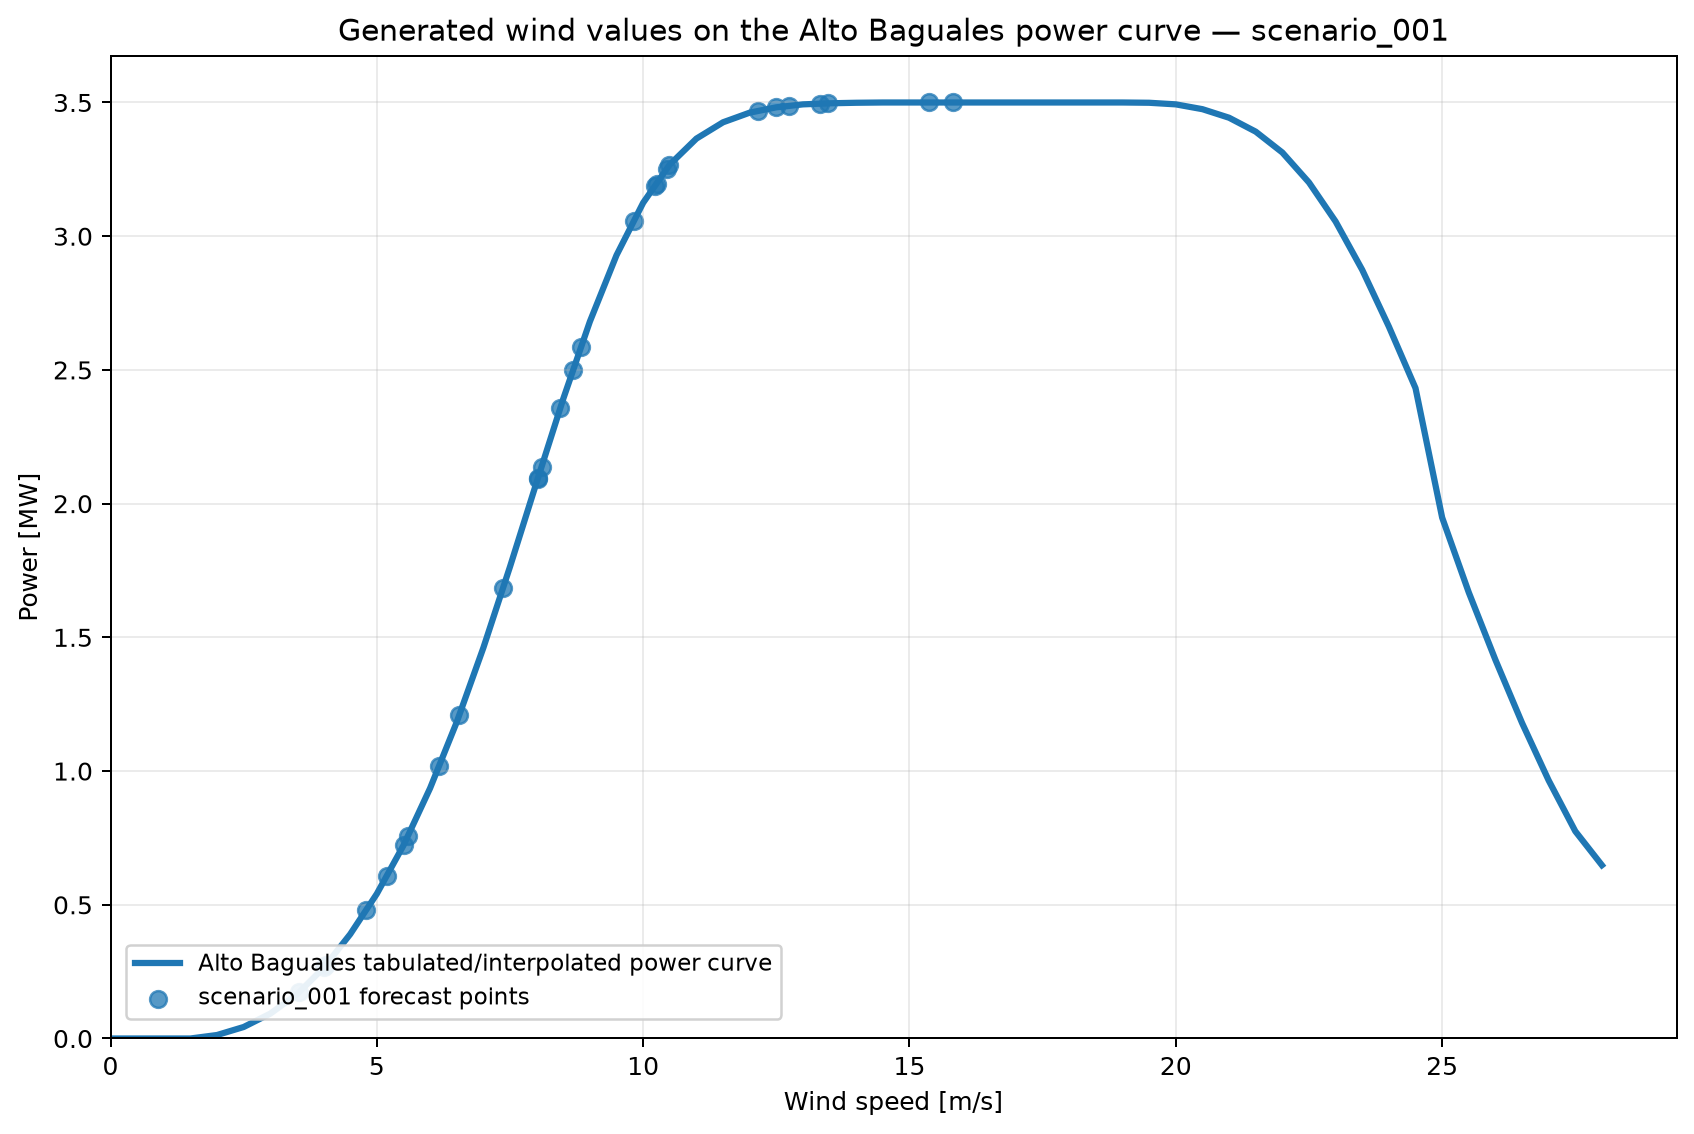

In [7]:
# Diagnóstico de la transformación:
# puntos (velocidad, potencia) del escenario sobre la curva de potencia.
power_curve_plot = visualize_result(
    result,
    mode="power_curve",
    scenario_number=1,
)

## 6. Caso 60/60

Para aproximadamente dos meses de contexto y dos meses de forecast:

In [ ]:
# Descomenta para ejecutar.
#
# result_60 = generate_wind_scenarios(
#     origin="2014-04-01",
#     historical_method="same_calendar_date",
#     context_len=60,
#     horizon_len=60,
# )

## 7. Caso de 100 escenarios con ventanas móviles

In [ ]:
# Descomenta para ejecutar.
#
# result_100 = generate_wind_scenarios(
#     origin="2014-04-01",
#     historical_method="moving_window",
#     context_len=32,
#     horizon_len=28,
#     n_scenarios=100,
#     window_radius_days=15,
#     min_start_distance_days=7,
# )

## 8. Uso independiente de `evaluation.py`

Si ya existen resultados y sólo quieres reconstruir el target observado:

```python
ground_truth = load_ground_truth(
    origin="2014-04-01",
    horizon_len=28,
)
```

o guardarlo directamente:

```python
save_ground_truth(
    origin="2014-04-01",
    horizon_len=28,
    output_dir="outputs/schaake/2014-04-01",
)
```

`ground_truth.csv` contiene:

```text
DATE,WIND,LEAD_DAY
```

y se alinea exactamente con los `horizon_len` días del forecast.

# Otras funciones útiles

#### genera gráficos de todos los escenarios con los quantiles 10, 50 y 90

In [ ]:
visualize_result(
    result,
    mode="single",
    all_quantiles=False,
    export_all=True,
    display_plot=False,
)

#### genera gráficos de todos los escenarios con todos los quantiles 

In [8]:
visualize_result(
    result,
    mode="single",
    all_quantiles=True,
    export_all=True,
    display_plot=False,
)

=== VISUALIZACIÓN ===
c:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\.venv\Scripts\python.exe -m wind_scenarios.cli.visualize --input_dir C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01 --data_path C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\data\wind_ab_daily.csv --mode single --all_quantiles --export_all
Plots guardados en: C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\outputs\schaake\2014-04-01\scenario_plots_all_quantiles


WindowsPath('C:/Users/Maximiliano/Desktop/ExpWindScenariesGeneration/outputs/schaake/2014-04-01/scenario_plots_all_quantiles')